# Comparative Study of Open-Source Text Analytics Libraries
### NLTK vs spaCy vs Stanford CoreNLP — Features, Ease of Use and Performance

**Course:** Text Analytics  |  **Student:** Gokulakannan S  |  **Programme:** Btech Artificial Intelligence and Data Science

---
**Objective.** Compare three widely used open-source NLP toolkits on (1) features, (2) ease of use and (3) performance, using the same text and the same tasks for every library.

**Tasks compared:** tokenization (with sentence splitting), POS tagging, lemmatization, named-entity recognition (NER).

**Data:** 100 movie reviews (NLTK `movie_reviews`) for speed; 500 sentences of the Penn Treebank sample (NLTK `treebank`) for POS accuracy.

**Notebook flow:** 1 Setup → 2 Data → 3 Feature demos → 4 Ease-of-use → 5 Performance (speed, accuracy, start-up/memory) → 6 Charts → 7 Conclusion.

> **Stanford CoreNLP** is a Java program. The notebook downloads it and talks to it through its local HTTP server. If Java or the download is not available, the CoreNLP cells are skipped and only NLTK and spaCy are measured. Run this notebook on Google Colab (Java is preinstalled) to get all three.

## 1. Setup

In [1]:
# Colab / fresh machine: uncomment the next line once
# !pip install -q nltk spacy psutil requests pandas matplotlib && python -m spacy download en_core_web_sm

import sys, os, time, json, statistics, subprocess, platform, datetime, inspect
import requests, psutil
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import nltk, spacy

for pkg in ['punkt','punkt_tab','averaged_perceptron_tagger','averaged_perceptron_tagger_eng',
            'maxent_ne_chunker','maxent_ne_chunker_tab','words','wordnet','omw-1.4','stopwords',
            'movie_reviews','treebank','vader_lexicon']:
    nltk.download(pkg, quiet=True)

try:
    spacy.load('en_core_web_sm')
except OSError:
    subprocess.run([sys.executable,'-m','spacy','download','en_core_web_sm'], check=True)

os.makedirs('figures', exist_ok=True)
META = {'python': platform.python_version(), 'nltk': nltk.__version__, 'spacy': spacy.__version__,
        'spacy_model': 'en_core_web_sm', 'cpu_count': os.cpu_count(),
        'platform': platform.platform(), 'date': datetime.date.today().isoformat()}
RESULTS = {'meta': META}
print(json.dumps(META, indent=2))

{
  "python": "3.12.3",
  "nltk": "3.10.3",
  "spacy": "3.8.16",
  "spacy_model": "en_core_web_sm",
  "cpu_count": 1,
  "platform": "Linux-6.18.44-fc-v139-x86_64-with-glibc2.39",
  "date": "2026-10-19"
}


## 2. Data

In [2]:
from nltk.corpus import movie_reviews, treebank

fileids = movie_reviews.fileids()[::20]            # every 20th review -> 100 mixed pos/neg docs
docs = [movie_reviews.raw(f) for f in fileids]
gold = [[(w, t) for w, t in s if t != '-NONE-'] for s in treebank.tagged_sents()[:500]]

RESULTS['data'] = {'n_docs': len(docs), 'total_chars': sum(map(len, docs)),
                   'avg_chars': round(sum(map(len, docs))/len(docs)),
                   'pos_sentences': len(gold), 'pos_tokens': sum(len(s) for s in gold)}
print(RESULTS['data'])
print('\nSample review:\n', docs[0][:300], '...')

{'n_docs': 100, 'total_chars': 380806, 'avg_chars': 3808, 'pos_sentences': 500, 'pos_tokens': 11784}

Sample review:
 plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the ...


## 3. Feature demonstration (same sentence, three libraries)

In [3]:
SAMPLE = ("Apple is looking at buying a U.K. startup for $1 billion. "
          "Sundar Pichai met Narendra Modi in New Delhi on 5 March 2024.")
print(SAMPLE)

Apple is looking at buying a U.K. startup for $1 billion. Sundar Pichai met Narendra Modi in New Delhi on 5 March 2024.


### 3.1 NLTK

In [4]:
from nltk import word_tokenize, sent_tokenize, pos_tag, ne_chunk
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import wordnet, stopwords
from nltk.sentiment import SentimentIntensityAnalyzer

def wn_pos(tag):
    return {'J': wordnet.ADJ, 'V': wordnet.VERB, 'R': wordnet.ADV}.get(tag[0], wordnet.NOUN)

lem = WordNetLemmatizer(); stem = PorterStemmer()
sents = sent_tokenize(SAMPLE)
toks = word_tokenize(SAMPLE)
tagged = pos_tag(toks)
print('Sentences :', len(sents))
print('Tokens    :', toks)
print('Stems     :', [stem.stem(t) for t in toks][:8], '...')
print('Lemmas    :', [lem.lemmatize(w, wn_pos(t)) for w, t in tagged][:8], '...')
print('POS       :', tagged[:8], '...')
tree = ne_chunk(tagged)
print('Entities  :', [(' '.join(w for w,_ in st.leaves()), st.label()) for st in tree if hasattr(st,'label')])
print('Sentiment (VADER):', SentimentIntensityAnalyzer().polarity_scores('The movie was surprisingly good!'))

Sentences : 2
Tokens    : ['Apple', 'is', 'looking', 'at', 'buying', 'a', 'U.K.', 'startup', 'for', '$', '1', 'billion', '.', 'Sundar', 'Pichai', 'met', 'Narendra', 'Modi', 'in', 'New', 'Delhi', 'on', '5', 'March', '2024', '.']
Stems     : ['appl', 'is', 'look', 'at', 'buy', 'a', 'u.k.', 'startup'] ...


Lemmas    : ['Apple', 'be', 'look', 'at', 'buy', 'a', 'U.K.', 'startup'] ...
POS       : [('Apple', 'NNP'), ('is', 'VBZ'), ('looking', 'VBG'), ('at', 'IN'), ('buying', 'VBG'), ('a', 'DT'), ('U.K.', 'NNP'), ('startup', 'NN')] ...


Entities  : [('Apple', 'GPE'), ('Sundar Pichai', 'PERSON'), ('Narendra Modi', 'PERSON'), ('New Delhi', 'GPE')]
Sentiment (VADER): {'neg': 0.0, 'neu': 0.357, 'pos': 0.643, 'compound': 0.6588}


### 3.2 spaCy

In [5]:
nlp_demo = spacy.load('en_core_web_sm')
doc = nlp_demo(SAMPLE)
print('Sentences :', len(list(doc.sents)))
print('Tokens    :', [t.text for t in doc])
print('Lemmas    :', [t.lemma_ for t in doc][:8], '...')
print('POS       :', [(t.text, t.tag_) for t in doc][:8], '...')
print('Entities  :', [(e.text, e.label_) for e in doc.ents])
print('Noun chunks:', [c.text for c in doc.noun_chunks])
print('Dependencies:', [(t.text, t.dep_, t.head.text) for t in doc][:8], '...')

Sentences : 2
Tokens    : ['Apple', 'is', 'looking', 'at', 'buying', 'a', 'U.K.', 'startup', 'for', '$', '1', 'billion', '.', 'Sundar', 'Pichai', 'met', 'Narendra', 'Modi', 'in', 'New', 'Delhi', 'on', '5', 'March', '2024', '.']
Lemmas    : ['Apple', 'be', 'look', 'at', 'buy', 'a', 'U.K.', 'startup'] ...
POS       : [('Apple', 'NNP'), ('is', 'VBZ'), ('looking', 'VBG'), ('at', 'IN'), ('buying', 'VBG'), ('a', 'DT'), ('U.K.', 'NNP'), ('startup', 'NN')] ...
Entities  : [('Apple', 'ORG'), ('U.K.', 'GPE'), ('$1 billion', 'MONEY'), ('Sundar Pichai', 'ORG'), ('Narendra Modi', 'PERSON'), ('New Delhi', 'GPE'), ('5 March 2024', 'DATE')]
Noun chunks: ['Apple', 'a U.K.', 'Sundar Pichai', 'Narendra Modi', 'New Delhi', '5 March']
Dependencies: [('Apple', 'nsubj', 'looking'), ('is', 'aux', 'looking'), ('looking', 'ROOT', 'looking'), ('at', 'prep', 'looking'), ('buying', 'pcomp', 'at'), ('a', 'det', 'U.K.'), ('U.K.', 'dobj', 'buying'), ('startup', 'advcl', 'looking')] ...


### 3.3 Stanford CoreNLP (Java server + REST)

In [6]:
import glob, shutil, urllib.request, zipfile
CORENLP_VERSION = '4.5.7'
CORENLP_URL = f'https://nlp.stanford.edu/software/stanford-corenlp-{CORENLP_VERSION}.zip'
PORT = 9000
BASE = f'http://localhost:{PORT}'
corenlp_ok, corenlp_proc, corenlp_startup = False, None, None

def start_corenlp():
    global corenlp_proc, corenlp_startup
    if shutil.which('java') is None:
        raise RuntimeError('Java not found (install JDK 8+).')
    dirs = glob.glob('stanford-corenlp-*/')
    if not dirs:
        print('Downloading CoreNLP (~500 MB)...')
        urllib.request.urlretrieve(CORENLP_URL, 'corenlp.zip')
        zipfile.ZipFile('corenlp.zip').extractall('.')
        dirs = glob.glob('stanford-corenlp-*/')
    t0 = time.perf_counter()
    corenlp_proc = subprocess.Popen(
        ['java', '-mx4g', '-cp', dirs[0] + '*', 'edu.stanford.nlp.pipeline.StanfordCoreNLPServer',
         '-port', str(PORT), '-timeout', '120000'], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(120):
        try:
            if requests.get(BASE + '/ready', timeout=2).ok: break
        except Exception: time.sleep(1)
    else:
        raise RuntimeError('CoreNLP server did not become ready.')
    corenlp_startup = time.perf_counter() - t0

def corenlp(text, annotators, **extra):
    props = {'annotators': annotators, 'outputFormat': 'json', **extra}
    r = requests.post(BASE, params={'properties': json.dumps(props)}, data=text.encode('utf-8'), timeout=600)
    r.raise_for_status()
    return r.json()

try:
    start_corenlp(); corenlp_ok = True
    j = corenlp(SAMPLE, 'tokenize,ssplit,pos,lemma,ner,depparse')
    print('Sentences :', len(j['sentences']))
    print('Tokens    :', [t['word'] for s in j['sentences'] for t in s['tokens']])
    print('Lemmas    :', [t['lemma'] for s in j['sentences'] for t in s['tokens']][:8], '...')
    print('POS       :', [(t['word'], t['pos']) for t in j['sentences'][0]['tokens']][:8], '...')
    print('Entities  :', [(m['text'], m['ner']) for s in j['sentences'] for m in s['entitymentions']])
    print(f'Server start-up: {corenlp_startup:.1f} s')
except Exception as e:
    print('CoreNLP skipped ->', e)

CoreNLP skipped -> <urlopen error [Errno -2] Name or service not known>


### 3.4 Feature matrix
Compiled from each project's official documentation (versions used: NLTK 3.x, spaCy 3.x with `en_core_web_sm`, CoreNLP 4.5.x). ✔ = built in, ◐ = partial / needs an add-on, ✘ = not provided.

In [7]:
features = pd.DataFrame([
 ['Implementation language',        'Python',            'Python / Cython',       'Java (REST, Python wrappers)'],
 ['Licence',                        'Apache 2.0',        'MIT',                   'GPL v3 (commercial licence available)'],
 ['Tokenization + sentence split',  '✔',                 '✔',                     '✔'],
 ['Stemming',                       '✔ (Porter, Snowball, Lancaster)', '✘ (lemmas only)', '✘ (lemmas only)'],
 ['Lemmatization',                  '✔ (WordNet, POS needed)', '✔',               '✔'],
 ['POS tagging',                    '✔',                 '✔',                     '✔'],
 ['Named-entity recognition',       '◐ (basic chunker)', '✔ (18 types)',          '✔ (incl. dates, numbers via SUTime)'],
 ['Dependency parsing',             '◐ (no pretrained model)', '✔',               '✔'],
 ['Constituency parsing',           '◐ (no pretrained model)', '✘ (plugin)',      '✔'],
 ['Coreference resolution',         '✘',                 '◐ (experimental)',      '✔'],
 ['Sentiment analysis',             '✔ (VADER lexicon)', '✘ (add-on)',            '✔ (neural)'],
 ['Open information extraction',    '✘',                 '✘',                     '✔ (OpenIE)'],
 ['Pretrained word vectors',        '✘',                 '✔ (md / lg models)',    '✘'],
 ['Built-in corpora / lexicons',    '✔ (WordNet, Brown, Treebank ...)', '✘',     '✘'],
 ['Train custom models',            '✔',                 '✔ (config system)',     '✔ (e.g. CRF NER)'],
 ['Languages with pretrained models','Limited tokenizers / stopwords', '~25 pipelines, 70+ tokenizers', '8 (EN, AR, ZH, FR, DE, HU, IT, ES)'],
 ['Primary design goal',            'Teaching / research','Production speed',      'Linguistic depth'],
], columns=['Feature','NLTK','spaCy','Stanford CoreNLP']).set_index('Feature')
RESULTS['features'] = features.reset_index().values.tolist()
features

,NLTK,spaCy,Stanford CoreNLP
Feature,,,
Implementation language,Python,Python / Cython,"Java (REST, Python wrappers)"
Licence,Apache 2.0,MIT,GPL v3 (commercial licence available)
Tokenization + sentence split,✔,✔,✔
Stemming,"✔ (Porter, Snowball, Lancaster)",✘ (lemmas only),✘ (lemmas only)
Lemmatization,"✔ (WordNet, POS needed)",✔,✔
POS tagging,✔,✔,✔
Named-entity recognition,◐ (basic chunker),✔ (18 types),"✔ (incl. dates, numbers via SUTime)"
Dependency parsing,◐ (no pretrained model),✔,✔
Constituency parsing,◐ (no pretrained model),✘ (plugin),✔


## 4. Ease of use

In [8]:
# Same job in each library: sentence -> tokens, POS tags, lemmas, entities
SNIP = {}
SNIP['NLTK'] = '''
from nltk import word_tokenize, pos_tag, ne_chunk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
lem = WordNetLemmatizer()
toks = word_tokenize(text)
tags = pos_tag(toks)
lemmas = [lem.lemmatize(w, {'J':wordnet.ADJ,'V':wordnet.VERB,'R':wordnet.ADV}.get(t[0], wordnet.NOUN)) for w,t in tags]
ents = [(' '.join(w for w,_ in s.leaves()), s.label()) for s in ne_chunk(tags) if hasattr(s,'label')]
'''
SNIP['spaCy'] = '''
import spacy
nlp = spacy.load('en_core_web_sm')
doc = nlp(text)
toks, tags = [t.text for t in doc], [t.tag_ for t in doc]
lemmas = [t.lemma_ for t in doc]
ents = [(e.text, e.label_) for e in doc.ents]
'''
SNIP['CoreNLP'] = '''
import requests, json
r = requests.post('http://localhost:9000', params={'properties': json.dumps({'annotators':'tokenize,ssplit,pos,lemma,ner','outputFormat':'json'})}, data=text.encode())
toks = [t for s in r.json()['sentences'] for t in s['tokens']]
tags, lemmas = [t['pos'] for t in toks], [t['lemma'] for t in toks]
ents = [(m['text'], m['ner']) for s in r.json()['sentences'] for m in s['entitymentions']]
'''
loc = {k: len([l for l in v.strip().splitlines() if l.strip()]) for k, v in SNIP.items()}
for k, v in SNIP.items():
    print(f'--- {k} ({loc[k]} lines) ---{v}')

--- NLTK (8 lines) ---
from nltk import word_tokenize, pos_tag, ne_chunk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
lem = WordNetLemmatizer()
toks = word_tokenize(text)
tags = pos_tag(toks)
lemmas = [lem.lemmatize(w, {'J':wordnet.ADJ,'V':wordnet.VERB,'R':wordnet.ADV}.get(t[0], wordnet.NOUN)) for w,t in tags]
ents = [(' '.join(w for w,_ in s.leaves()), s.label()) for s in ne_chunk(tags) if hasattr(s,'label')]

--- spaCy (6 lines) ---
import spacy
nlp = spacy.load('en_core_web_sm')
doc = nlp(text)
toks, tags = [t.text for t in doc], [t.tag_ for t in doc]
lemmas = [t.lemma_ for t in doc]
ents = [(e.text, e.label_) for e in doc.ents]

--- CoreNLP (5 lines) ---
import requests, json
r = requests.post('http://localhost:9000', params={'properties': json.dumps({'annotators':'tokenize,ssplit,pos,lemma,ner','outputFormat':'json'})}, data=text.encode())
toks = [t for s in r.json()['sentences'] for t in s['tokens']]
tags, lemmas = [t['pos'] for t in toks], [t['lemma'] 

In [9]:
ease = pd.DataFrame({
 'Install':               ['pip install nltk', 'pip install spacy', 'Download ~0.5 GB zip + JDK'],
 'Extra downloads':       ['Per-task data via nltk.download (6+ packages here)', '1 model (python -m spacy download)', 'Models bundled in the zip'],
 'Lines for the common job': [loc['NLTK'], loc['spaCy'], loc['CoreNLP']],
 'Needs a running server':['No', 'No', 'Yes (HTTP, JVM)'],
 'Output object':         ['Lists / tuples / Trees', 'Doc, Token, Span objects', 'JSON'],
 'Documentation':         ['Free book + API docs', 'Extensive guides + course', 'Reference docs, fewer tutorials'],
}, index=['NLTK','spaCy','Stanford CoreNLP']).T
RESULTS['ease'] = {'loc': loc, 'table': ease.reset_index().values.tolist()}
ease

,NLTK,spaCy,Stanford CoreNLP
Install,pip install nltk,pip install spacy,Download ~0.5 GB zip + JDK
Extra downloads,Per-task data via nltk.download (6+ packages h...,1 model (python -m spacy download),Models bundled in the zip
Lines for the common job,8,6,5
Needs a running server,No,No,"Yes (HTTP, JVM)"
Output object,Lists / tuples / Trees,"Doc, Token, Span objects",JSON
Documentation,Free book + API docs,Extensive guides + course,"Reference docs, fewer tutorials"


## 5. Performance
Methodology: identical 100 documents for every library, one document per call, median of repeated runs after a warm-up call. Throughput is reported as **documents/second** and **tokens/second** (each library's own tokenizer defines "token", so tokens/s is indicative; docs/s is the fairer figure).
Pipelines compared: **Tokenization** (incl. sentence split), **+ POS tagging**, **+ lemmatization + NER**.

In [10]:
def bench(fn, docs, repeats=3):
    fn(docs[0])                                    # warm-up
    times, ntok = [], 0
    for _ in range(repeats):
        t = time.perf_counter(); ntok = sum(fn(d) for d in docs); times.append(time.perf_counter() - t)
    sec = statistics.median(times)
    return {'seconds': round(sec, 3), 'docs_per_sec': round(len(docs)/sec, 2), 'tokens': ntok, 'tokens_per_sec': round(ntok/sec)}

# ---- NLTK
def nltk_tok(d):  return len(word_tokenize(d))
def nltk_pos(d):  return len(pos_tag(word_tokenize(d)))
def nltk_full(d):
    tg = pos_tag(word_tokenize(d))
    _ = [lem.lemmatize(w, wn_pos(t)) for w, t in tg]
    ne_chunk(tg)
    return len(tg)

# ---- spaCy
nlp_tok  = spacy.blank('en'); nlp_tok.add_pipe('sentencizer')
nlp_pos  = spacy.load('en_core_web_sm', exclude=['parser','ner','lemmatizer'])
nlp_full = spacy.load('en_core_web_sm', exclude=['parser'])          # tagger + lemmatizer + NER
def sp_tok(d):  return len(nlp_tok(d))
def sp_pos(d):  return len(nlp_pos(d))
def sp_full(d): return len(nlp_full(d))
def sp_full_pipe(ds):
    return sum(len(x) for x in nlp_full.pipe(ds, batch_size=16))

R = {'NLTK': {}, 'spaCy': {}}
R['NLTK']['Tokenization']       = bench(nltk_tok, docs)
R['NLTK']['+ POS tagging']      = bench(nltk_pos, docs)
R['NLTK']['+ Lemma + NER']      = bench(nltk_full, docs, repeats=2)
R['spaCy']['Tokenization']      = bench(sp_tok, docs)
R['spaCy']['+ POS tagging']     = bench(sp_pos, docs)
R['spaCy']['+ Lemma + NER']     = bench(sp_full, docs)
# spaCy with batching (nlp.pipe), a recommended production pattern
t = time.perf_counter(); n = sp_full_pipe(docs); s = time.perf_counter() - t
R['spaCy (nlp.pipe)'] = {'+ Lemma + NER': {'seconds': round(s,3), 'docs_per_sec': round(len(docs)/s,2), 'tokens': n, 'tokens_per_sec': round(n/s)}}

if corenlp_ok:
    def cn(ann):
        return lambda d: sum(len(s['tokens']) for s in corenlp(d, ann)['sentences'])
    R['CoreNLP'] = {
        'Tokenization':  bench(cn('tokenize,ssplit'), docs),
        '+ POS tagging': bench(cn('tokenize,ssplit,pos'), docs),
        '+ Lemma + NER': bench(cn('tokenize,ssplit,pos,lemma,ner'), docs, repeats=2),
    }
RESULTS['speed'] = R
rows = [(lib, task, v['docs_per_sec'], v['tokens_per_sec'], v['seconds']) for lib, d in R.items() for task, v in d.items()]
speed_df = pd.DataFrame(rows, columns=['Library','Task','Docs/sec','Tokens/sec','Total sec (100 docs)'])
speed_df

,Library,Task,Docs/sec,Tokens/sec,Total sec (100 docs)
0,NLTK,Tokenization,420.84,316376,0.238
1,NLTK,+ POS tagging,45.20,33982,2.212
2,NLTK,+ Lemma + NER,1.38,1035,72.650
3,spaCy,Tokenization,337.39,269305,0.296
4,spaCy,+ POS tagging,27.95,22309,3.578
5,spaCy,+ Lemma + NER,15.18,12114,6.589
6,spaCy (nlp.pipe),+ Lemma + NER,16.97,13544,5.893


### 5.2 POS-tagging accuracy on Penn Treebank sentences (gold standard)

In [11]:
# All three libraries use the Penn Treebank tag set, so tags are directly comparable.
# Pre-tokenised input is used so that token boundaries match the gold data exactly.
from spacy.tokens import Doc
def acc(pred, gold):
    ok = tot = 0
    for p, g in zip(pred, gold):
        for a, b in zip(p, g):
            ok += (a == b[1]); tot += 1
    return ok / tot

words = [[w for w, _ in s] for s in gold]
pred_nltk  = [[t for _, t in pos_tag(ws)] for ws in words]
pred_spacy = [[t.tag_ for t in nlp_pos(Doc(nlp_pos.vocab, words=ws))] for ws in words]
ACC = {'NLTK': acc(pred_nltk, gold), 'spaCy': acc(pred_spacy, gold)}

if corenlp_ok:
    txt = '\n'.join(' '.join(ws) for ws in words)
    j = corenlp(txt, 'tokenize,ssplit,pos', **{'tokenize.whitespace': 'true', 'ssplit.eolonly': 'true'})
    pred_cn = [[t['pos'] for t in s['tokens']] for s in j['sentences']]
    if len(pred_cn) == len(gold) and all(len(a)==len(b) for a,b in zip(pred_cn, gold)):
        ACC['CoreNLP'] = acc(pred_cn, gold)
RESULTS['pos_accuracy'] = {k: round(v*100, 2) for k, v in ACC.items()}
print({k: f'{v*100:.2f}%' for k, v in ACC.items()})
print('Note: the Treebank sample overlaps with the training data of several taggers, so these numbers are optimistic; use them for relative comparison.')

{'NLTK': '96.58%', 'spaCy': '95.88%'}
Note: the Treebank sample overlaps with the training data of several taggers, so these numbers are optimistic; use them for relative comparison.


### 5.3 Start-up time and memory

In [12]:
# Each library is loaded in a fresh process so that memory is not shared with this notebook.
probe = {
 'NLTK': '''
import time, psutil; p = psutil.Process(); r0 = p.memory_info().rss; t = time.perf_counter()
import nltk; from nltk import word_tokenize, pos_tag, ne_chunk; from nltk.stem import WordNetLemmatizer
tg = pos_tag(word_tokenize('John lives in London.')); ne_chunk(tg); WordNetLemmatizer().lemmatize('dogs')
print(time.perf_counter()-t, (p.memory_info().rss-r0)/1e6)''',
 'spaCy': '''
import time, psutil; p = psutil.Process(); r0 = p.memory_info().rss; t = time.perf_counter()
import spacy; nlp = spacy.load('en_core_web_sm'); nlp('John lives in London.')
print(time.perf_counter()-t, (p.memory_info().rss-r0)/1e6)''',
}
START = {}
for k, code_ in probe.items():
    out = subprocess.run([sys.executable, '-c', code_], capture_output=True, text=True).stdout.split()
    START[k] = {'startup_sec': round(float(out[0]), 2), 'memory_mb': round(float(out[1]))}
if corenlp_ok and corenlp_proc is not None:
    rss = psutil.Process(corenlp_proc.pid).memory_info().rss / 1e6
    START['CoreNLP'] = {'startup_sec': round(corenlp_startup, 1), 'memory_mb': round(rss)}
RESULTS['startup'] = START
pd.DataFrame(START).T.rename(columns={'startup_sec':'Start-up (s)','memory_mb':'Memory (MB)'})

,Start-up (s),Memory (MB)
NLTK,5.36,324.0
spaCy,1.33,143.0


## 6. Charts

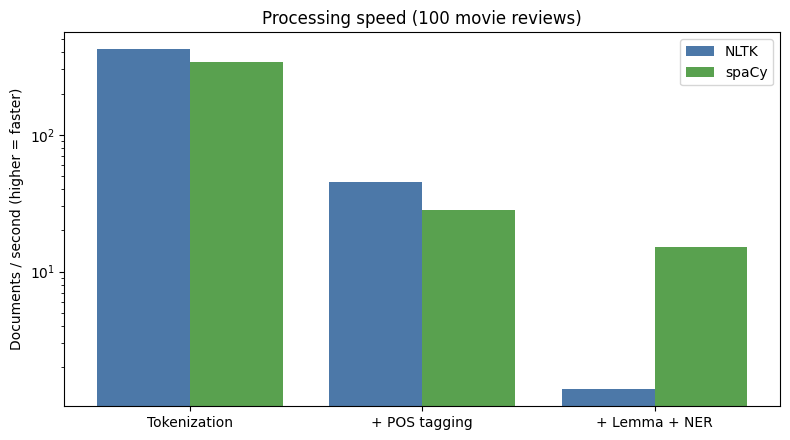

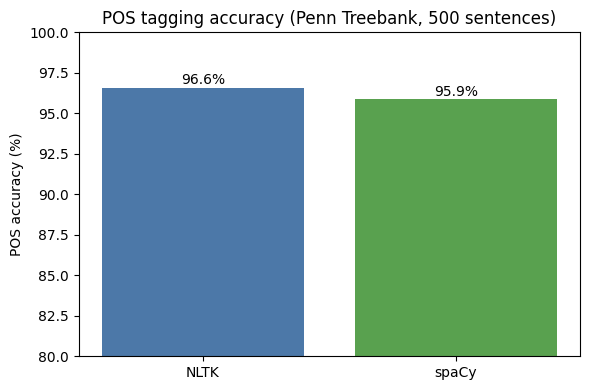

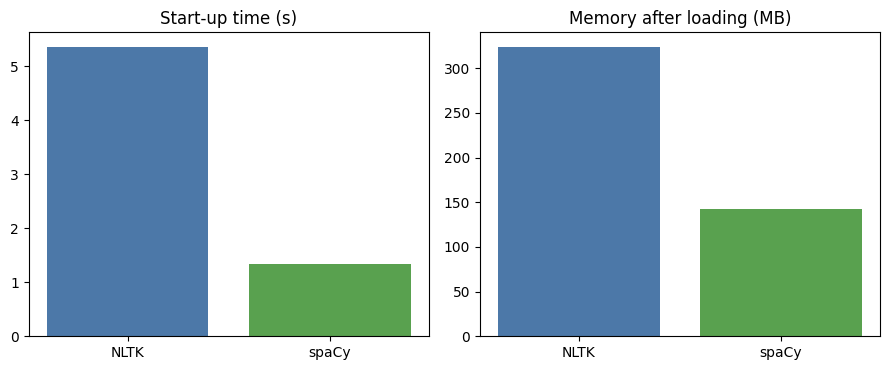

In [13]:
colors = {'NLTK': '#4C78A8', 'spaCy': '#59A14F', 'CoreNLP': '#E15759', 'spaCy (nlp.pipe)': '#8CD17D'}
tasks = ['Tokenization', '+ POS tagging', '+ Lemma + NER']
libs = [l for l in ['NLTK', 'spaCy', 'CoreNLP'] if l in R]

fig, ax = plt.subplots(figsize=(8, 4.5))
w = 0.8 / len(libs)
for i, l in enumerate(libs):
    ax.bar(np.arange(3) + i*w, [R[l][t]['docs_per_sec'] for t in tasks], w, label=l, color=colors[l])
ax.set_xticks(np.arange(3) + w*(len(libs)-1)/2); ax.set_xticklabels(tasks)
ax.set_ylabel('Documents / second (higher = faster)'); ax.set_yscale('log')
ax.set_title('Processing speed (100 movie reviews)'); ax.legend(); plt.tight_layout()
plt.savefig('figures/speed.png', dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
names = list(ACC); vals = [ACC[n]*100 for n in names]
ax.bar(names, vals, color=[colors[n] for n in names])
for i, v in enumerate(vals): ax.text(i, v + 0.2, f'{v:.1f}%', ha='center')
ax.set_ylim(80, 100); ax.set_ylabel('POS accuracy (%)'); ax.set_title('POS tagging accuracy (Penn Treebank, 500 sentences)')
plt.tight_layout(); plt.savefig('figures/pos_accuracy.png', dpi=160); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(9, 3.8))
names = list(START)
axs[0].bar(names, [START[n]['startup_sec'] for n in names], color=[colors[n] for n in names]); axs[0].set_title('Start-up time (s)')
axs[1].bar(names, [START[n]['memory_mb'] for n in names], color=[colors[n] for n in names]); axs[1].set_title('Memory after loading (MB)')
plt.tight_layout(); plt.savefig('figures/startup_memory.png', dpi=160); plt.show()

## 7. Qualitative scoring and conclusion
Ease-of-use and feature scores are the author's judgement (1 = poor, 5 = excellent) based on sections 3 and 4; speed is **not** scored here because it depends on the task (see section 5) and CoreNLP is only measured when the notebook is run where Java is available.

In [14]:
score = pd.DataFrame({
 'Feature breadth':      {'NLTK': 3, 'spaCy': 4, 'CoreNLP': 5},
 'Ease of use':          {'NLTK': 4, 'spaCy': 5, 'CoreNLP': 3},
 'Learning / teaching':  {'NLTK': 5, 'spaCy': 4, 'CoreNLP': 3},
 'Production readiness': {'NLTK': 2, 'spaCy': 5, 'CoreNLP': 4},
}).T
RESULTS['scores'] = score.reset_index().values.tolist()
display(score)
print(score.sum())

,NLTK,spaCy,CoreNLP
Feature breadth,3,4,5
Ease of use,4,5,3
Learning / teaching,5,4,3
Production readiness,2,5,4


NLTK       14
spaCy      18
CoreNLP    15
dtype: int64


### Conclusion
* **NLTK** is the best choice for *learning* and *research prototyping*: it bundles corpora, lexicons (WordNet, VADER) and many classic algorithms with a simple API, but its pretrained NER / parsing is limited. In our runs it was actually the fastest for tokenization and POS-only, but about 10x slower than spaCy once lemmatization + `ne_chunk` NER were added.
* **spaCy** is the best *all-round* choice for applications: one-line pipelines, consistent objects, much faster than NLTK for the full lemma + NER pipeline on CPU (and faster still with `nlp.pipe` batching), pretrained dependency parsing and NER.
* **Stanford CoreNLP** offers the deepest *linguistic analysis* (constituency parsing, coreference, OpenIE, rich temporal NER) but needs Java, a server and more memory, and the GPL licence matters for commercial use.

**Recommendation:** use NLTK to learn the concepts, spaCy to build the product, and CoreNLP when coreference / constituency / OpenIE are specifically required.

### Limitations
Small sample (100 documents), one machine, `en_core_web_sm` (small model), Penn Treebank sample overlaps with training data of some taggers, CoreNLP measured through HTTP (adds network and JSON overhead). Results show relative behaviour, not absolute benchmarks.

In [15]:
with open('results.json', 'w', encoding='utf-8') as f:
    json.dump(RESULTS, f, indent=2, ensure_ascii=False, default=str)
if corenlp_proc: corenlp_proc.terminate()
print('Saved results.json and figures/*.png')

Saved results.json and figures/*.png
